# Caso m?dico educativo: diagn?stico de tumores mamarios con Wisconsin

### Pipeline reproducible de clasificaci?n binaria

Este laboratorio recorre un flujo completo de Machine Learning con **Breast Cancer Wisconsin (Diagnostic)**, disponible localmente en scikit-learn. Practicaremos an?lisis de datos, separaci?n estratificada, validaci?n cruzada, selecci?n de umbral por costos y evaluaci?n final.

## Contexto, fuente y l?mites

El conjunto contiene 569 observaciones y 30 mediciones calculadas a partir de im?genes digitalizadas de aspiraciones con aguja fina. La etiqueta original distingue tumores `malignant` y `benign`; no contiene informaci?n personal identificable. scikit-learn distribuye una copia del conjunto de UCI, por lo que este laboratorio no necesita descargar archivos.

**Uso exclusivamente educativo.** Es una muestra peque?a e hist?rica; no representa por s? sola la poblaci?n cl?nica actual, no incorpora el proceso de atenci?n ni consecuencias de tratamiento y no est? validada para uso m?dico. El modelo no debe emplearse para diagnosticar ni tomar decisiones cl?nicas. Las m?tricas de este ejercicio no demuestran utilidad m?dica.

## Objetivo y mapa de etiquetas

Trataremos `malignant` como clase positiva (`1`) para que sensibilidad/recall mida la detecci?n de casos malignos en este ejercicio. `benign` ser? `0`. Esta elecci?n hace expl?cito el costo pedag?gico de los falsos negativos; no sustituye una decisi?n cl?nica.

Secuencia: cargar y revisar ? separar train/validaci?n/test ? comparar modelos con CV solo en train ? elegir un umbral con validaci?n ? evaluar una sola vez en test.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
COST_FP = 1
COST_FN = 20

current_dir = Path.cwd()
PROJECT_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir
if not (PROJECT_ROOT / "notebooks").is_dir():
    raise FileNotFoundError("Abre el notebook desde la raiz del proyecto o su carpeta notebooks/.")

bunch = load_breast_cancer(as_frame=True)
X = bunch.data.copy()
y = pd.Series((bunch.target.to_numpy() == 0).astype(np.int8), index=X.index, name="malignant")
print(f"Filas: {len(X)} | variables: {X.shape[1]} | positivos (malignant): {int(y.sum())}")
print("Fuente cargada desde scikit-learn; no se requiere descarga.")

Filas: 569 | variables: 30 | positivos (malignant): 212
Fuente cargada desde scikit-learn; no se requiere descarga.


## 1. Conocer los datos antes de modelar

Revisa dimensiones, nombres de variables, tipos, valores faltantes y distribuci?n de clases. Una fila representa una muestra del conjunto; no debe interpretarse como el historial completo de una persona.

In [2]:
print("Nombres originales de clase:", list(bunch.target_names))
print("Forma de X:", X.shape)
print("Tipos de datos:")
display(X.dtypes.value_counts().rename("cantidad").to_frame())
print("Valores faltantes:", int(X.isna().sum().sum()))
print("Filas duplicadas:", int(X.duplicated().sum()))
print("Balance de clases (0=benign, 1=malignant):")
display(y.value_counts().sort_index().rename(index={0: "benign", 1: "malignant"}).to_frame("muestras"))
display(X.describe().T.head(8))
assert X.shape == (569, 30)
assert X.isna().sum().sum() == 0

Nombres originales de clase: [np.str_('malignant'), np.str_('benign')]
Forma de X: (569, 30)
Tipos de datos:


,cantidad
float64,30


Valores faltantes: 0
Filas duplicadas: 0
Balance de clases (0=benign, 1=malignant):


,muestras
malignant,
benign,357
malignant,212


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012


## 2. Separar datos sin contaminar la evaluaci?n

Reservamos 20% para test y 20% para validaci?n; ambas particiones son estratificadas. El 60% restante se usa para la validaci?n cruzada y el ajuste. Test no se usa para escoger modelo, variables ni umbral. La semilla fija facilita reproducir el ejercicio.

In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=SEED
)

print(f"Train: {len(X_train)} | validacion: {len(X_val)} | test: {len(X_test)}")
print("Proporcion positiva:", {
    "train": round(float(y_train.mean()), 3),
    "validacion": round(float(y_val.mean()), 3),
    "test": round(float(y_test.mean()), 3),
})
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

Train: 341 | validacion: 114 | test: 114
Proporcion positiva: {'train': 0.372, 'validacion': 0.377, 'test': 0.368}


## 3. Comparar referencias con validaci?n cruzada

Comparamos regresi?n log?stica y Random Forest con folds estratificados **solo dentro de train**. El escalado est? dentro del pipeline de la regresi?n log?stica, as? cada fold ajusta su propio escalador y evitamos data leakage. Usamos recall, precision, F1 y ROC-AUC; ninguna m?trica aislada basta para juzgar un sistema m?dico.

In [4]:
model_candidates = {
    "Regresion logistica": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED)
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, class_weight="balanced",
            random_state=SEED, n_jobs=-1,
        ),
    ),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = []
for model_name, estimator in model_candidates.items():
    scores = cross_validate(
        estimator, X_train, y_train, cv=cv, scoring=scoring,
        return_train_score=False, n_jobs=1,
    )
    row = {"modelo": model_name}
    for metric in scoring:
        row[f"{metric}_media"] = float(scores[f"test_{metric}"].mean())
        row[f"{metric}_desv"] = float(scores[f"test_{metric}"].std())
    cv_rows.append(row)
cv_results = pd.DataFrame(cv_rows).sort_values(
    ["f1_media", "recall_media", "roc_auc_media"], ascending=False
).reset_index(drop=True)
display(cv_results.round(3))

,modelo,recall_media,recall_desv,precision_media,precision_desv,f1_media,f1_desv,roc_auc_media,roc_auc_desv
0,Regresion logistica,0.938,0.039,0.967,0.016,0.952,0.027,0.994,0.008
1,Random Forest,0.946,0.052,0.928,0.055,0.935,0.034,0.987,0.011


### Elecci?n del modelo

La regla de este laboratorio prioriza el F1 medio de CV, con recall y ROC-AUC como desempate. Es una regla did?ctica predefinida, no una recomendaci?n universal. La validaci?n y el test permanecen separados de esta comparaci?n.

In [5]:
selected_name = str(cv_results.loc[0, "modelo"])
selected_model = clone(model_candidates[selected_name])
selected_model.fit(X_train, y_train)
print("Modelo elegido con CV:", selected_name)
print("Clases aprendidas:", selected_model.classes_)

Modelo elegido con CV: Regresion logistica
Clases aprendidas: [0 1]


## 4. Elegir un umbral con la validaci?n

La clasificaci?n por defecto usa 0.5, pero ese umbral no siempre refleja los costos del problema. Para el ejercicio suponemos un costo de 1 para falso positivo y 20 para falso negativo, reflejando que queremos priorizar sensibilidad en la clase `malignant`. Buscamos el menor costo en validaci?n; si hay empate, preferimos menos falsos negativos y luego el umbral mayor. Son supuestos did?cticos y no costos cl?nicos validados.

In [6]:
def positive_probability(model, features):
    positive_indices = np.flatnonzero(model.classes_ == 1)
    if len(positive_indices) != 1:
        raise ValueError("El modelo no contiene exactamente una clase positiva (1).")
    return model.predict_proba(features)[:, int(positive_indices[0])]


def cost_counts(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    return int(fp), int(fn), int(COST_FP * fp + COST_FN * fn)

val_probabilities = positive_probability(selected_model, X_val)
threshold_rows = []
for threshold in np.arange(0.10, 0.901, 0.01):
    val_prediction = (val_probabilities >= threshold).astype(np.int8)
    fp, fn, total_cost = cost_counts(y_val, val_prediction)
    threshold_rows.append({"umbral": float(threshold), "FP": fp, "FN": fn, "costo": total_cost})
threshold_results = pd.DataFrame(threshold_rows)
best_row = threshold_results.sort_values(
    ["costo", "FN", "umbral"], ascending=[True, True, False]
).iloc[0]
best_threshold = float(best_row["umbral"])
print(f"Umbral elegido en validacion: {best_threshold:.2f}")
print(f"Costo de validacion: {int(best_row['costo'])} (FP={int(best_row['FP'])}, FN={int(best_row['FN'])})")

Umbral elegido en validacion: 0.10
Costo de validacion: 13 (FP=13, FN=0)


## 5. Evaluaci?n final en test

Ahora medimos una sola vez en el conjunto reservado. Mostramos el umbral fijo 0.5 y el umbral escogido previamente en validaci?n. No volvemos a ajustar el modelo ni a mover el umbral despu?s de ver estos resultados. Si el costo del umbral elegido no mejora en test, es una demostraci?n de variabilidad de la validaci?n, no una raz?n para retocar test.

In [7]:
test_probabilities = positive_probability(selected_model, X_test)
test_rows = []
test_predictions = {}
for name, threshold in (("umbral_0.50", 0.50), ("umbral_validacion", best_threshold)):
    predictions = (test_probabilities >= threshold).astype(np.int8)
    fp, fn, total_cost = cost_counts(y_test, predictions)
    test_predictions[name] = predictions
    test_rows.append({
        "escenario": name,
        "umbral": float(threshold),
        "precision_malignant": float(precision_score(y_test, predictions, zero_division=0)),
        "recall_malignant": float(recall_score(y_test, predictions, zero_division=0)),
        "f1_malignant": float(f1_score(y_test, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, test_probabilities)),
        "average_precision": float(average_precision_score(y_test, test_probabilities)),
        "FP": fp, "FN": fn, "costo": total_cost,
    })
test_results = pd.DataFrame(test_rows)
display(test_results.round(3))
print("Reporte para el umbral elegido (clases benign=0, malignant=1):")
print(classification_report(
    y_test, test_predictions["umbral_validacion"],
    labels=[0, 1], target_names=["benign", "malignant"], zero_division=0,
))

,escenario,umbral,precision_malignant,recall_malignant,f1_malignant,roc_auc,average_precision,FP,FN,costo
0,umbral_0.50,0.5,0.976,0.952,0.964,0.995,0.994,1,2,41
1,umbral_validacion,0.1,0.854,0.976,0.911,0.995,0.994,7,1,27


Reporte para el umbral elegido (clases benign=0, malignant=1):
              precision    recall  f1-score   support

      benign       0.98      0.90      0.94        72
   malignant       0.85      0.98      0.91        42

    accuracy                           0.93       114
   macro avg       0.92      0.94      0.93       114
weighted avg       0.94      0.93      0.93       114



### Leer la matriz de confusi?n

Con el orden expl?cito `[benign, malignant]`, la celda siguiente presenta filas como clase real y columnas como predicci?n. Para la clase positiva `malignant`, los falsos negativos son casos malignos clasificados como benignos. En un contexto real la evaluaci?n exigir?a dise?o cl?nico, validaci?n externa y supervisi?n especializada.

In [8]:
chosen_predictions = test_predictions["umbral_validacion"]
cm = confusion_matrix(y_test, chosen_predictions, labels=[0, 1])
cm_display = pd.DataFrame(
    cm,
    index=pd.Index(["real benign", "real malignant"], name="real / prediccion"),
    columns=["pred benign", "pred malignant"],
)
display(cm_display)
print(f"Sensibilidad (recall malignant): {recall_score(y_test, chosen_predictions):.3f}")
print(f"Falsos negativos en test: {int(cm[1, 0])}")

,pred benign,pred malignant
real / prediccion,,
real benign,65,7
real malignant,1,41


Sensibilidad (recall malignant): 0.976
Falsos negativos en test: 1


## 6. Curva ROC

La curva ROC resume sensibilidad frente a tasa de falsos positivos para distintos umbrales. El AUC eval?a ordenamiento, no calibraci?n ni beneficio cl?nico. Se calcula en test solo para describir la evaluaci?n final; no se utiliza para cambiar el modelo.

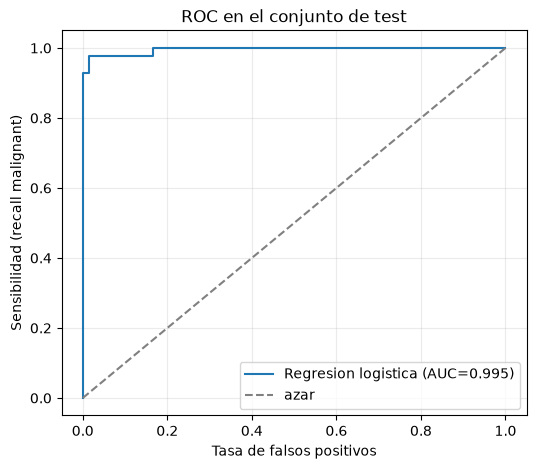

In [9]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"{selected_name} (AUC={roc_auc_score(y_test, test_probabilities):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="azar")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad (recall malignant)", title="ROC en el conjunto de test")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 7. Inspecci?n de variables (no causal)

Para ilustrar interpretabilidad mostramos coeficientes absolutos si se eligi? regresi?n log?stica, o importancia por impureza si se eligi? Random Forest. Son se?ales internas del modelo, no evidencia causal ni una explicaci?n cl?nica; la correlaci?n entre variables puede alterar su orden.

,valor absoluto del coeficiente
worst texture,1.355329
mean concave points,1.104290
radius error,1.025939
worst symmetry,0.951861
worst radius,0.813413
worst area,0.794784
area error,0.782246
worst concavity,0.768948
mean concavity,0.762093
compactness error,0.759123


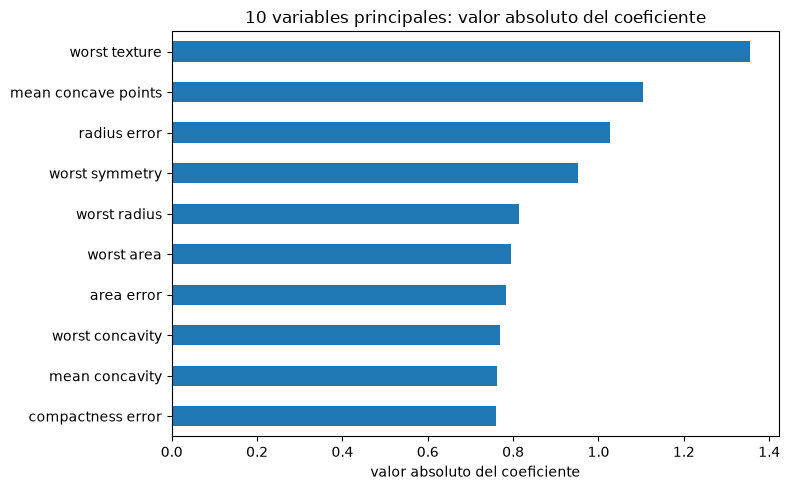

In [10]:
fitted_estimator = selected_model.steps[-1][1]
if hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(fitted_estimator.coef_[0])
    importance_kind = "valor absoluto del coeficiente"
elif hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_kind = "importancia por impureza"
else:
    raise TypeError(f"No hay una importancia disponible para {type(fitted_estimator).__name__}.")
feature_importance = pd.Series(importance_values, index=X.columns, name=importance_kind).sort_values(ascending=False)
display(feature_importance.head(10).to_frame())
ax = feature_importance.head(10).sort_values().plot.barh(figsize=(8, 5), title=f"10 variables principales: {importance_kind}")
ax.set_xlabel(importance_kind)
plt.tight_layout()
plt.show()

## 8. Guardar resultados reproducibles

Guardamos m?tricas y configuraci?n del experimento en una carpeta independiente. No se guarda ni se mezcla este modelo con los artefactos agr?colas del proyecto.

In [11]:
output_dir = PROJECT_ROOT / "reports" / "pipeline_prueba_wisconsin"
output_dir.mkdir(parents=True, exist_ok=True)
test_results.to_csv(output_dir / "metricas.csv", index=False)
threshold_results.to_csv(output_dir / "validacion_umbrales.csv", index=False)
config = {
    "dataset": "Breast Cancer Wisconsin (Diagnostic), bundled with scikit-learn",
    "n_samples": int(len(X)),
    "n_features": int(X.shape[1]),
    "positive_class": "malignant",
    "negative_class": "benign",
    "model_selected_by_train_cv": selected_name,
    "random_state": SEED,
    "split": {"train": 0.60, "validation": 0.20, "test": 0.20},
    "threshold_selected_on_validation": best_threshold,
    "cost_false_positive": COST_FP,
    "cost_false_negative": COST_FN,
    "test_metrics": test_rows[1],
    "use_limit": "Educational only; not for diagnosis or clinical decisions.",
}
with (output_dir / "config.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, ensure_ascii=False, indent=2, allow_nan=False)
print("Resultados escritos en:", output_dir.relative_to(PROJECT_ROOT))

Resultados escritos en: reports\pipeline_prueba_wisconsin


## Actividad para estudiantes

1. ?C?mo cambian falsos positivos, falsos negativos y costo al variar `COST_FN`?
2. ?Por qu? se ajusta el escalador dentro de un pipeline y no antes de CV?
3. ?Qu? evidencia adicional har?a falta antes de siquiera considerar un modelo cl?nico?
4. Repite el ejercicio con otro `random_state` y observa cu?nto var?an las m?tricas. No selecciones el resultado m?s favorable.

In [12]:
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert 0.10 <= best_threshold <= 0.90
assert test_results["roc_auc"].between(0, 1).all()
assert test_results["recall_malignant"].between(0, 1).all()
assert (output_dir / "metricas.csv").is_file()
assert (output_dir / "validacion_umbrales.csv").is_file()
assert (output_dir / "config.json").is_file()
print("Comprobaciones completadas: particiones sin solapamiento, m?tricas v?lidas y reporte guardado.")

Comprobaciones completadas: particiones sin solapamiento, m?tricas v?lidas y reporte guardado.


## Cierre

El caso conecta habilidades del curso con una aplicaci?n m?dica realista en escala did?ctica, sin afirmar que el modelo sea apto para la pr?ctica cl?nica. La separaci?n por pacientes no aplica a este conjunto tabular porque no se ofrece un identificador de paciente; esta limitaci?n debe tenerse presente al interpretar sus muestras.

In [13]:
print(f"Modelo educativo: {selected_name}")
print(f"Umbral fijado con validacion: {best_threshold:.2f}")
print("M?tricas finales y configuraci?n:", output_dir.relative_to(PROJECT_ROOT))
print("No usar estas predicciones para diagn?stico ni decisiones cl?nicas.")

Modelo educativo: Regresion logistica
Umbral fijado con validacion: 0.10
M?tricas finales y configuraci?n: reports\pipeline_prueba_wisconsin
No usar estas predicciones para diagn?stico ni decisiones cl?nicas.
